# Wholesale Customers: Denetimsiz Öğrenme Projesi

Wholesale Customers veri seti, toptancı müşterilerinin farklı ürün kategorilerindeki yıllık harcamalarını içerir. Bu projenin amacı müşterileri harcama davranışlarına göre incelemek ve benzer müşterileri kümelemektir. Denetimsiz öğrenmede modele önceden tanımlanmış bir hedef değişken verilmez; veri içindeki örüntüler araştırılır.

## Sütunların açıklaması

| Sütun | Açıklama |
|---|---|
| Channel | Müşterinin satış kanalı |
| Region | Müşterinin bulunduğu bölge |
| Fresh | Yıllık taze ürün harcaması |
| Milk | Yıllık süt ürünleri harcaması |
| Grocery | Yıllık market ürünleri harcaması |
| Frozen | Yıllık dondurulmuş ürün harcaması |
| Detergents_Paper | Yıllık deterjan ve kâğıt ürünleri harcaması |
| Delicassen | Yıllık şarküteri ürünleri harcaması |

`Channel` ve `Region` sayısal görünse de bir miktar veya ölçüm değil, kategorik bilgi taşır. Kümeleme modelinde müşterilerin harcama profiline odaklanmak için bu iki sütunu özellik olarak kullanmayacağız.

## 1. Kütüphanelerin yüklenmesi

Önce veri işleleme ve görselleştirme için gerekli kütüphaneleri yüklüyoruz. `sklearn` bileşenleri ihtiyaç duyulan bölümlerde ayrıca eklenecek.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("Set2")
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

## 2. Veri setinin yüklenmesi

`head()` fonksiyonu, veri setinin ilk satırlarını hızlıca incelememizi ve sütunların beklediğimiz biçimde geldiğini kontrol etmemizi sağlar.

In [2]:
df = pd.read_csv("Wholesale customers data.csv")
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


## 3. Veri setini genel olarak tanıma

Boyut, sütun adları ve veri tipleri ilk veri kalite kontrolünün temel parçalarıdır. Sayısal harcama sütunlarına ek olarak `Channel` ve `Region` kodları bulunur; bu ikisini kategorik olarak yorumlayacağız.

In [3]:
df.shape

(440, 8)

In [4]:
df.columns

Index(['Channel', 'Region', 'Fresh', 'Milk', 'Grocery', 'Frozen',
       'Detergents_Paper', 'Delicassen'],
      dtype='str')

In [5]:
df.dtypes

Channel             int64
Region              int64
Fresh               int64
Milk                int64
Grocery             int64
Frozen              int64
Detergents_Paper    int64
Delicassen          int64
dtype: object

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


Bu veri setinde **440 satır ve 8 sütun** vardır. Altı harcama sütunu sayısal nicel değişkendir; `Channel` ve `Region` ise sayıyla kodlanmış kategorik değişkenlerdir.

## 4. Eksik değer kontrolü

Eksik değerler, uzaklık hesaplarını ve makine öğrenmesi modellerini etkileyebilir. Bu nedenle model kurmadan önce hem sütun bazında hem de toplam eksik değeri kontrol ediyoruz.

In [7]:
display(df.isnull().sum())
print("Toplam eksik değer sayısı:", df.isnull().sum().sum())

Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

Toplam eksik değer sayısı: 0


Çıktıya göre veri setinde eksik değer yoktur; bu nedenle ayrıca bir doldurma işlemi gerekmemektedir.

## 5. Tekrar eden satırlar

Tekrar eden kayıtlar bazı müşteri profillerinin olduğundan daha sık görünmesine ve kümeleri etkilemesine neden olabilir. Önce sayıyı kontrol ediyor, ancak ancak varsa siliyoruz.

In [8]:
duplicate_count = df.duplicated().sum()
print("Tekrar eden kayıt sayısı:", duplicate_count)
if duplicate_count > 0:
    display(df[df.duplicated(keep=False)].sort_values(list(df.columns)))
    df = df.drop_duplicates().copy()
    print("Tekrar eden kayıtlar kaldırıldı. Yeni boyut:", df.shape)
else:
    print("Tekrar eden kayıt bulunmadığı için veri seti değiştirilmedi.")

Tekrar eden kayıt sayısı: 0
Tekrar eden kayıt bulunmadığı için veri seti değiştirilmedi.


## 6. Temel istatistikler

`count` gözlem sayısını, `mean` ortalamayı, `std` yayılımı gösterir. `min` ve `max` uç değerleri; %25, %50 (medyan) ve %75 ise dağılımın çeyreklerini özetler.

In [9]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Channel,440.00,1.32,0.47,1.00,1.00,1.00,2.00,2.00
Region,440.00,2.54,0.77,1.00,2.00,3.00,3.00,3.00
Fresh,440.00,"12,000.30","12,647.33",3.00,"3,127.75","8,504.00","16,933.75","112,151.00"
Milk,440.00,"5,796.27","7,380.38",55.00,"1,533.00","3,627.00","7,190.25","73,498.00"
Grocery,440.00,"7,951.28","9,503.16",3.00,"2,153.00","4,755.50","10,655.75","92,780.00"
Frozen,440.00,"3,071.93","4,854.67",25.00,742.25,"1,526.00","3,554.25","60,869.00"
Detergents_Paper,440.00,"2,881.49","4,767.85",3.00,256.75,816.50,"3,922.00","40,827.00"
Delicassen,440.00,"1,524.87","2,820.11",3.00,408.25,965.50,"1,820.25","47,943.00"


## 7. Channel ve Region incelemesi

Bu iki değişken müşterilerin kanal ve bölge dağılımını anlamaya yardım eder. Kodları harcama miktarı gibi yorumlamamak gerekir.

Channel
1    298
2    142
Name: count, dtype: int64

Region
1     77
2     47
3    316
Name: count, dtype: int64

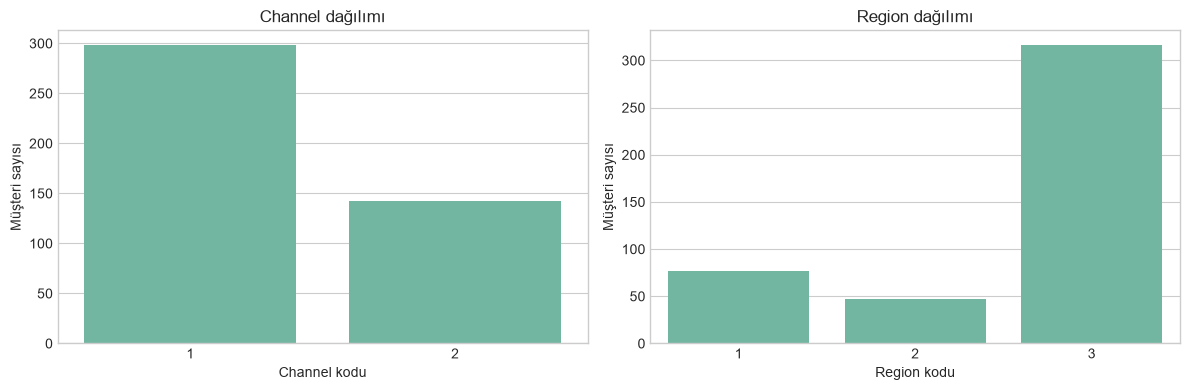

In [10]:
display(df["Channel"].value_counts().sort_index())
display(df["Region"].value_counts().sort_index())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="Channel", ax=axes[0])
axes[0].set_title("Channel dağılımı")
axes[0].set_xlabel("Channel kodu")
axes[0].set_ylabel("Müşteri sayısı")
sns.countplot(data=df, x="Region", ax=axes[1])
axes[1].set_title("Region dağılımı")
axes[1].set_xlabel("Region kodu")
axes[1].set_ylabel("Müşteri sayısı")
plt.tight_layout()
plt.show()

Dağılımda Channel=1 daha sık görülür. Region=3, gözlemlerin açık ara en yoğun olduğu bölgedir; diğer iki bölgenin müşteri sayısı daha düşüktür.

## 8. Harcama değişkenlerinin dağılımları

Harcama sütunlarını ayrı bir listede toplayarak yalnızca modelde kullanacağımız nicel özellikleri inceliyoruz. Histogramlar şekli, çarpıklığı ve çok yüksek harcama yapan müşterileri görmemizi sağlar.

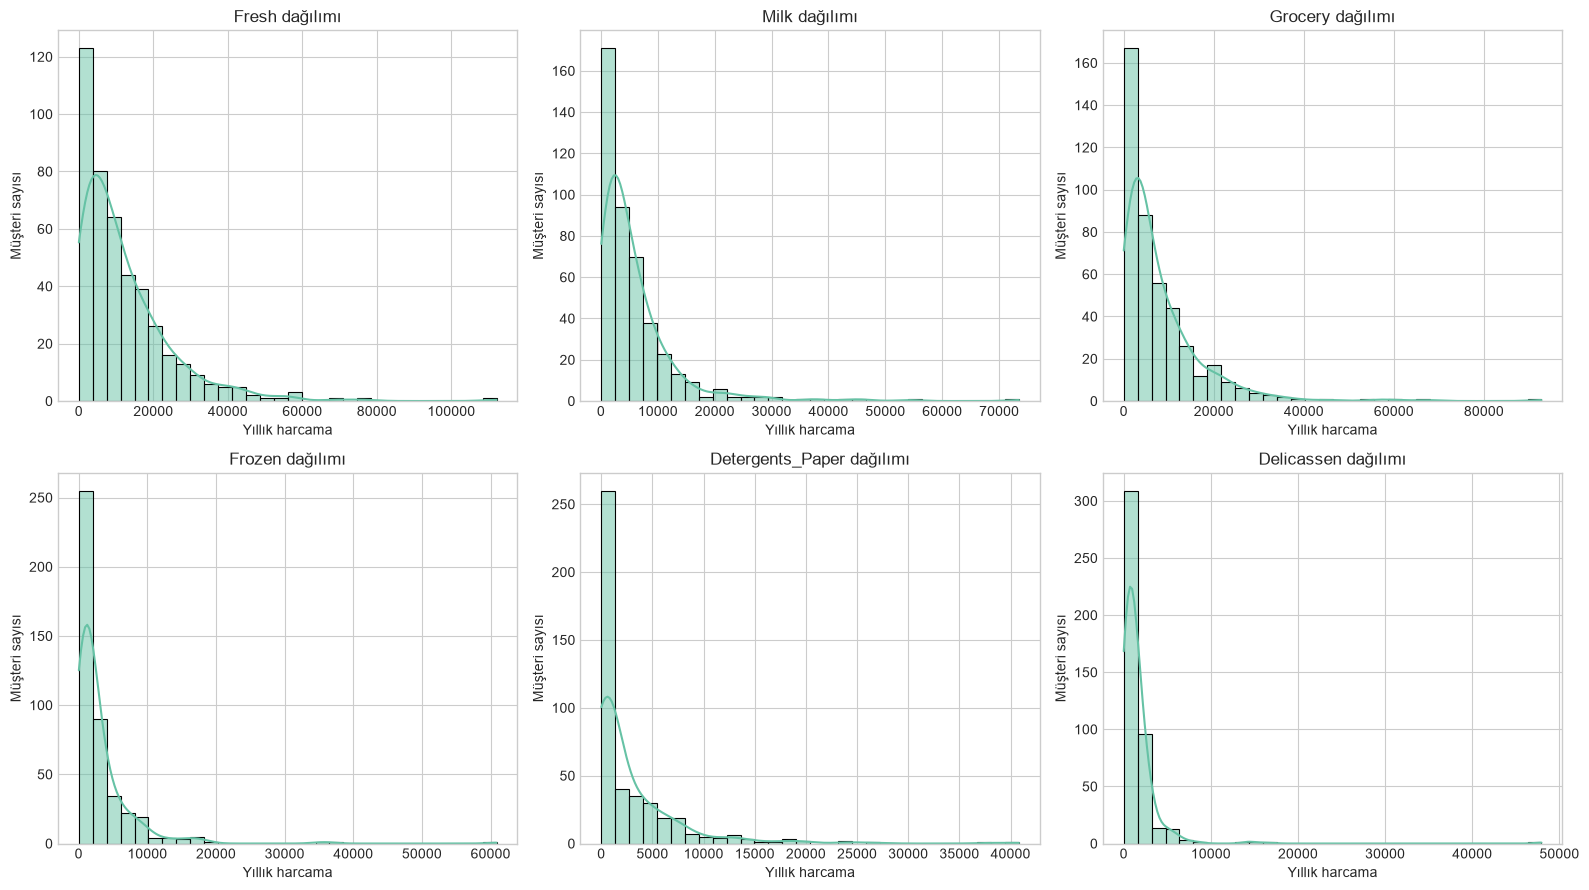

In [11]:
spending_cols = [
    "Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for col, ax in zip(spending_cols, axes.flat):
    sns.histplot(df[col], bins=30, kde=True, ax=ax)
    ax.set_title(f"{col} dağılımı")
    ax.set_xlabel("Yıllık harcama")
    ax.set_ylabel("Müşteri sayısı")
plt.tight_layout()
plt.show()

Histogramlar simetrik değildir: harcama değişkenlerinin tamamı sağa çarpıktır. Özellikle yüksek harcamalı az sayıdaki müşteri uzun bir sağ kuyruk oluşturur.

## 9. Boxplot ile aykırı değer incelemesi

Boxplot medyanı, çeyrekleri ve çeyrekler arası aralığın dışında kalan olası aykırı değerleri göstermeye yardım eder. Bu aşamada aykırı değerleri silmiyoruz; önce onların gerçek müşteri davranışı olabileceğini kabul ederek gözlemliyoruz.

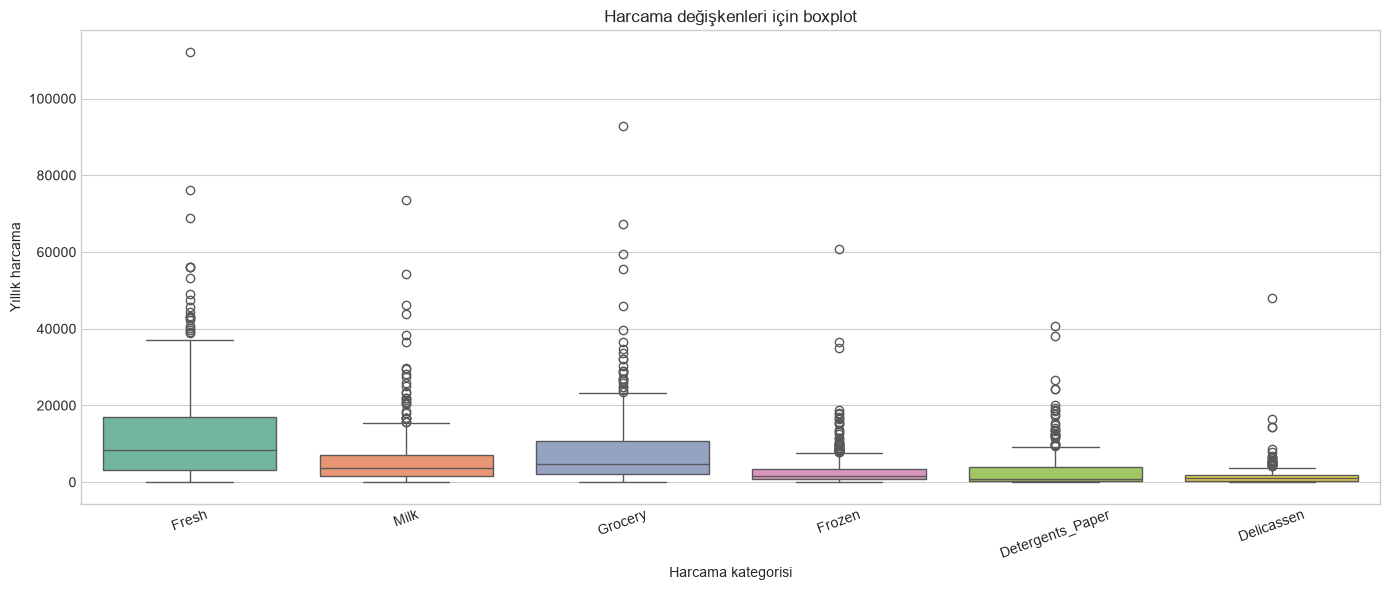

In [12]:
plt.figure(figsize=(14, 6))
sns.boxplot(data=df[spending_cols])
plt.title("Harcama değişkenleri için boxplot")
plt.xlabel("Harcama kategorisi")
plt.ylabel("Yıllık harcama")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### Aykırı değerlerin Region'a göre dağılımı

Boxplottaki aykırı gözlemleri IQR kuralı ile sayısallaştırıyoruz: bir değer alt sınırın altında veya üst sınırın üzerinde ise aykırı kabul edilir. Her harcama kategorisi için bu müşterilerin hangi `Region` kodunda daha çok bulunduğunu bar grafiklerle inceleyeceğiz.

In [13]:
# Her harcama değişkeni için IQR tabanlı aykırı değerleri buluyoruz.
region_order = sorted(df["Region"].unique())
outlier_region_counts = pd.DataFrame(index=region_order)
outlier_summary_rows = []

for col in spending_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    is_outlier = (df[col] < lower_bound) | (df[col] > upper_bound)

    counts = (
        df.loc[is_outlier, "Region"]
        .value_counts()
        .reindex(region_order, fill_value=0)
    )
    outlier_region_counts[col] = counts
    max_count = counts.max()
    max_regions = ", ".join(map(str, counts[counts == max_count].index))
    outlier_summary_rows.append({
        "Harcama kategorisi": col,
        "Toplam aykırı değer": int(is_outlier.sum()),
        "En çok aykırı değer bulunan Region": max_regions,
        "Bu Regiondaki aykırı değer sayısı": int(max_count),
        "Alt sınır": lower_bound,
        "Üst sınır": upper_bound,
    })

display(outlier_region_counts.T.rename_axis("Harcama kategorisi"))
display(pd.DataFrame(outlier_summary_rows).round(2))


,1,2,3
Harcama kategorisi,,,
Fresh,3,0,17
Milk,5,3,20
Grocery,5,3,16
Frozen,4,7,32
Detergents_Paper,6,6,18
Delicassen,3,1,23


,Harcama kategorisi,Toplam aykırı değer,En çok aykırı değer bulunan Region,Bu Regiondaki aykırı değer sayısı,Alt sınır,Üst sınır
0,Fresh,20,3,17,"-17,581.25","37,642.75"
1,Milk,28,3,20,"-6,952.88","15,676.12"
2,Grocery,24,3,16,"-10,601.12","23,409.88"
3,Frozen,43,3,32,"-3,475.75","7,772.25"
4,Detergents_Paper,30,3,18,"-5,241.12","9,419.88"
5,Delicassen,27,3,23,"-1,709.75","3,938.25"


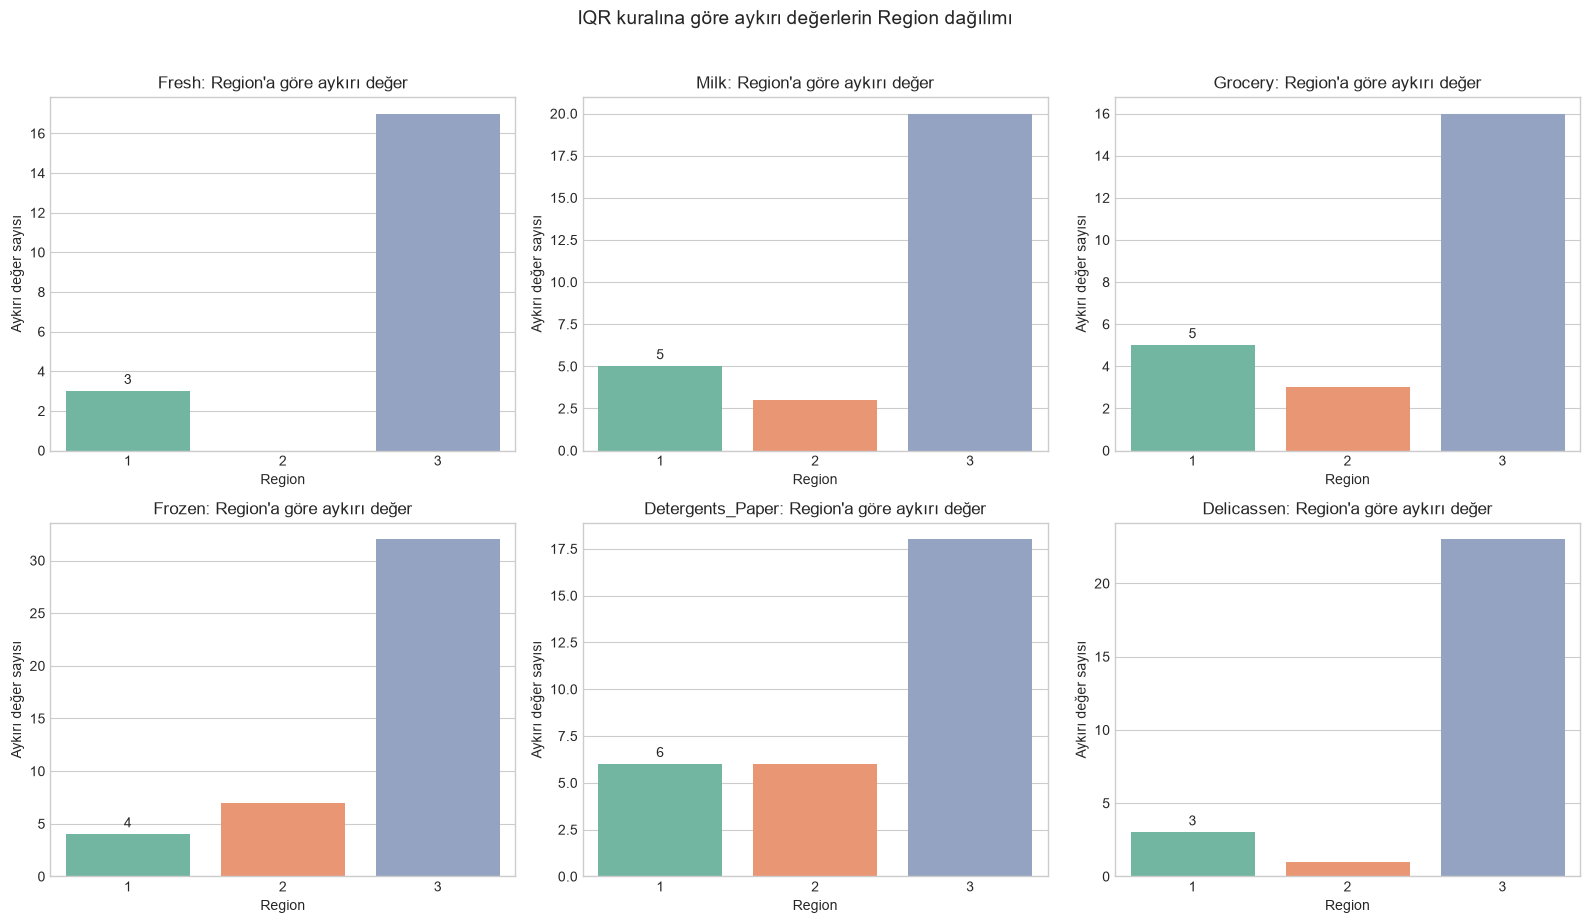

Fresh: en çok aykırı değer Region 3'de (17 kayıt).
Milk: en çok aykırı değer Region 3'de (20 kayıt).
Grocery: en çok aykırı değer Region 3'de (16 kayıt).
Frozen: en çok aykırı değer Region 3'de (32 kayıt).
Detergents_Paper: en çok aykırı değer Region 3'de (18 kayıt).
Delicassen: en çok aykırı değer Region 3'de (23 kayıt).


In [14]:
# Her grafikte barlar, ilgili harcama sütunundaki aykırı değerlerin Region bazındaki sayısını gösterir.
fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharey=False)

for col, ax in zip(spending_cols, axes.flat):
    plot_data = (
        outlier_region_counts[col]
        .rename("Aykırı değer sayısı")
        .rename_axis("Region")
        .reset_index()
    )
    sns.barplot(
        data=plot_data,
        x="Region",
        y="Aykırı değer sayısı",
        hue="Region",
        palette="Set2",
        legend=False,
        ax=ax,
    )
    ax.set_title(f"{col}: Region'a göre aykırı değer")
    ax.set_xlabel("Region")
    ax.set_ylabel("Aykırı değer sayısı")
    ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)

plt.suptitle("IQR kuralına göre aykırı değerlerin Region dağılımı", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

for row in outlier_summary_rows:
    print(
        f"{row['Harcama kategorisi']}: en çok aykırı değer "
        f"Region {row['En çok aykırı değer bulunan Region']}'de "
        f"({row['Bu Regiondaki aykırı değer sayısı']} kayıt)."
    )


Bu veri setinde tüm harcama kategorilerinde en yüksek ham aykırı değer sayısı **Region 3**'tedir. Ancak Region 3 toplam müşteri sayısı bakımından da en büyük bölge olduğu için, bu sonuç ham adet olarak yorumlanmalıdır; bölgeleri adil oranlarla karşılaştırmak istenirse bölge başına aykırı değer oranı ayrıca hesaplanabilir.

Boxplotlarda üst tarafta çok sayıda olası aykırı gözlem görünmektedir. Bu değerler, veri hatası olduğuna dair kanıt olmadığı için korunacak; sonraki adımda log dönüşümü ile etkileri azaltılacaktır.

## 10. Korelasyon analizi

Korelasyon matrisi harcama kategorilerinin birlikte değişme eğilimini gösterir. Korelasyon nedensellik anlamına gelmez; yalnızca doğrusal ilişkinin yönü ve gücü hakkında fikir verir.

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Fresh,1.00,0.10,-0.01,0.35,-0.10,0.24
Milk,0.10,1.00,0.73,0.12,0.66,0.41
Grocery,-0.01,0.73,1.00,-0.04,0.92,0.21
Frozen,0.35,0.12,-0.04,1.00,-0.13,0.39
Detergents_Paper,-0.10,0.66,0.92,-0.13,1.00,0.07
Delicassen,0.24,0.41,0.21,0.39,0.07,1.00


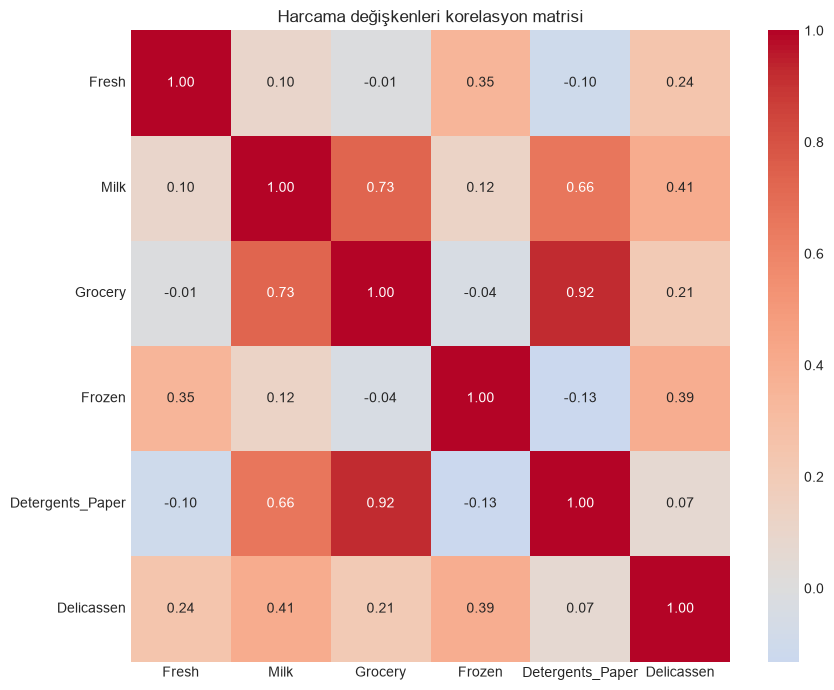

In [15]:
correlation_matrix = df[spending_cols].corr()
display(correlation_matrix)

plt.figure(figsize=(9, 7))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Harcama değişkenleri korelasyon matrisi")
plt.tight_layout()
plt.show()

Özellikle `Grocery`, `Milk` ve `Detergents_Paper` arasında güçlü pozitif ilişkiler gözlenir. Bu, ilgili kategorilere yüksek harcama yapan müşterilerin diğerinde de yüksek olma eğiliminde olduğunu gösterir.

## 11. Çarpıklık kontrolü

Çarpıklık, dağılımın simetriden ne kadar uzaklaştığını özetler. Uzaklık tabanlı denetimsiz öğrenme yöntemlerinde çok çarpık değişkenler mesafeleri orantısız etkileyebileceği için dönüşüm yararlı olabilir.

In [16]:
skewness = df[spending_cols].skew().sort_values(ascending=False)
display(skewness.to_frame("Skewness"))

,Skewness
Delicassen,11.15
Frozen,5.91
Milk,4.05
Detergents_Paper,3.63
Grocery,3.59
Fresh,2.56


Çarpıklık değerleri pozitiftir ve özellikle `Delicassen` ile `Frozen` belirgin biçimde sağa çarpıktır. Bu nedenle harcama sütunlarına log dönüşümü uygulayacağız.

## 12. Log dönüşümü

`log1p(x)`, `log(1 + x)` hesaplar. Bu yaklaşım sıfır değerlerinde de güvenlidir ve büyük harcama değerlerinin ölçek üzerindeki baskınlığını azaltarak dağılımları daha dengeli hâle getirir.

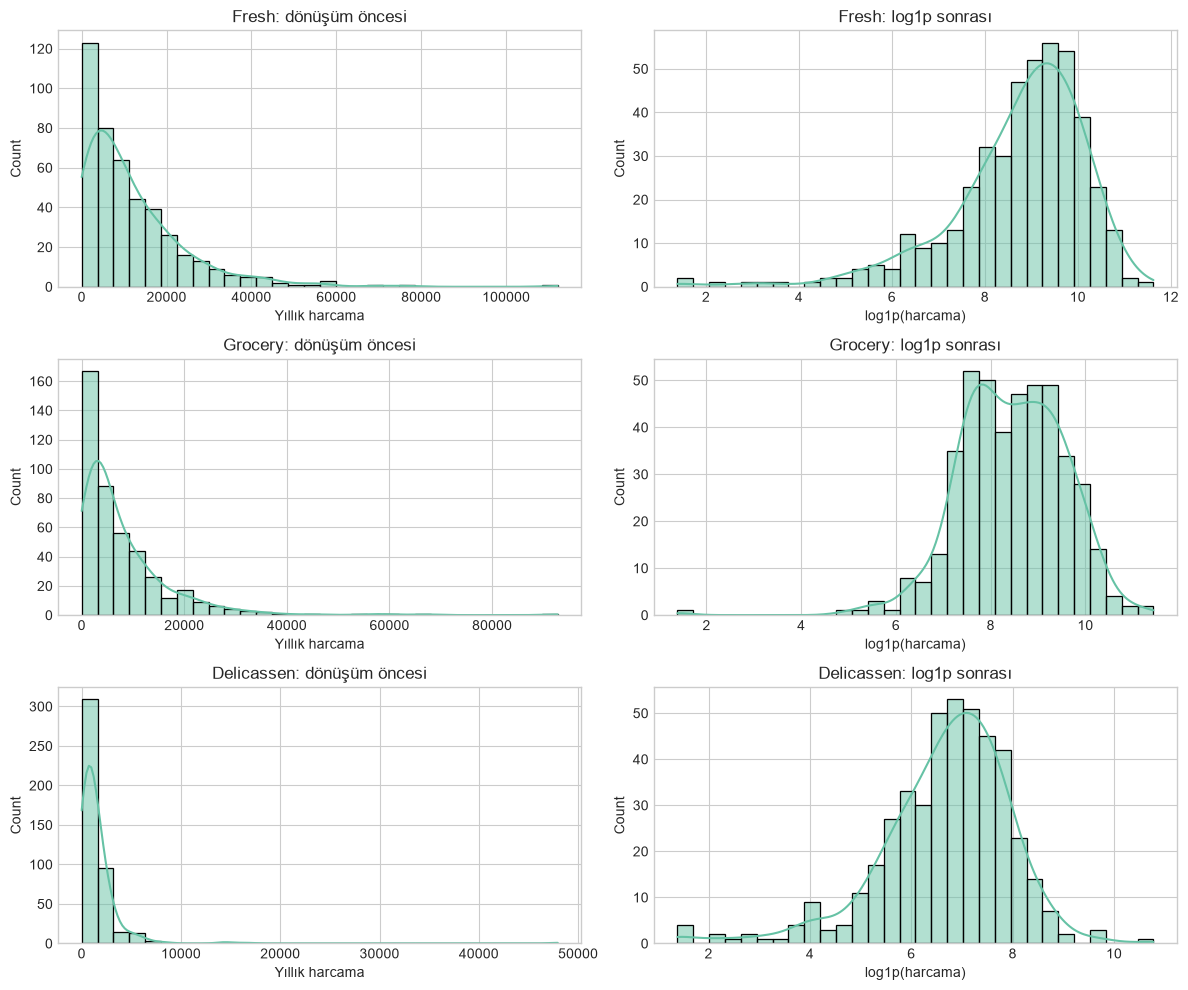

In [17]:
X_log = np.log1p(df[spending_cols])

compare_cols = ["Fresh", "Grocery", "Delicassen"]
fig, axes = plt.subplots(len(compare_cols), 2, figsize=(12, 10))
for row, col in enumerate(compare_cols):
    sns.histplot(df[col], bins=30, kde=True, ax=axes[row, 0])
    axes[row, 0].set_title(f"{col}: dönüşüm öncesi")
    axes[row, 0].set_xlabel("Yıllık harcama")
    sns.histplot(X_log[col], bins=30, kde=True, ax=axes[row, 1])
    axes[row, 1].set_title(f"{col}: log1p sonrası")
    axes[row, 1].set_xlabel("log1p(harcama)")
plt.tight_layout()
plt.show()

Dönüşümden sonra uzun sağ kuyruklar kısalır ve dağılımlar daha sıkışık hâle gelir. Bu, kümelerin aşırı harcama yapan birkaç müşteriden daha az etkilenmesine yardım eder.

## 13. Özelliklerin ölçeklendirilmesi

K-Means uzaklık tabanlı olduğu için büyük sayılı sütunların modeli gereğinden fazla etkilemesini önlemek gerekir. `StandardScaler`, her özelliği ortalaması 0 ve standart sapması 1 olacak şekilde ölçeklendirir.

In [18]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)
X_scaled_df = pd.DataFrame(X_scaled, columns=spending_cols, index=df.index)
X_scaled_df.head()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,0.49,0.98,0.44,-1.51,0.64,0.41
1,0.09,0.99,0.65,0.13,0.77,0.63
2,0.02,0.89,0.45,0.38,0.80,1.78
3,0.52,-0.96,-0.08,1.14,-0.33,0.63
4,0.88,0.44,0.40,0.76,0.40,1.46


## 14. K-Means kümeleme

K-Means, gözlemleri belirlenen sayıda kümeye ayırır ve her kümenin merkezini güncelleyerek çalışır. Her gözlem en yakın merkeze atanır; amaç küme içindeki uzaklıkları küçük tutmaktır. Küme sayısı başlangıçta bilinmediği için önce farklı K değerlerini karşılaştıracağız.

### Elbow Method

Inertia, gözlemlerin kendi küme merkezlerine olan kareli uzaklıklarının toplamıdır. K arttıkça inertia düşer; grafikteki belirgin kırılma noktası makul bir K seçimine yardımcı olur.

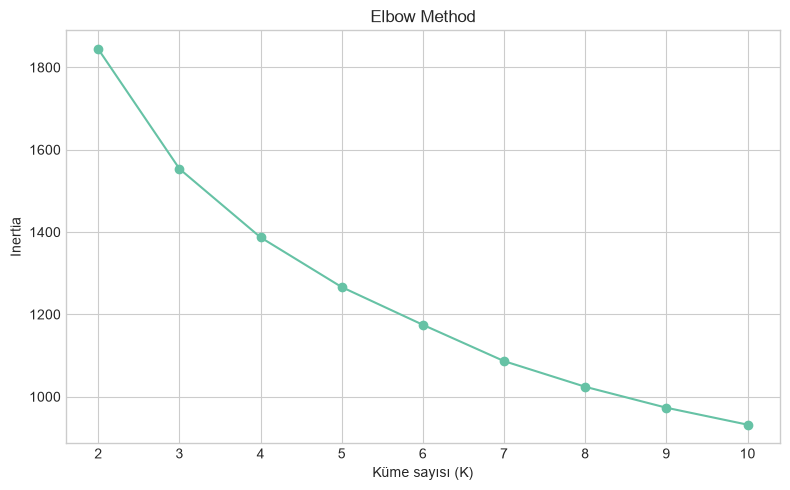

In [19]:
from sklearn.cluster import KMeans

k_values = range(2, 11)
inertias = []
for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=20)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.title("Elbow Method")
plt.xlabel("Küme sayısı (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()

### K değerlerini tüm metriklerle karşılaştırma

Her K için dört ölçütü aynı tabloda hesaplıyoruz: `Inertia` Elbow grafiğinin temelidir ve düşük olması beklenir; `Silhouette` ile `Calinski-Harabasz (CH)` yüksek olduğunda daha iyidir. `Davies-Bouldin (DB)` ise düşük olduğunda kümelerin daha iyi ayrıldığını gösterir. Metrikleri birlikte değerlendirmek, yalnızca tek bir skora göre karar vermekten daha güvenlidir.

,K,Inertia (Elbow),Silhouette Score,Davies-Bouldin (DB),Calinski-Harabasz (CH)
0,2,"1,844.06",0.29,1.35,189.05
1,3,"1,553.41",0.26,1.35,152.84
2,4,"1,386.86",0.19,1.54,131.32
3,5,"1,266.15",0.19,1.48,118.00
4,6,"1,174.54",0.20,1.41,108.30
5,7,"1,086.36",0.20,1.39,103.21
6,8,"1,024.05",0.19,1.39,97.39
7,9,973.14,0.20,1.38,92.28
8,10,932.00,0.19,1.34,87.56


En yüksek Silhouette Score: K=2
En düşük Davies-Bouldin (DB): K=10
En yüksek Calinski-Harabasz (CH): K=2


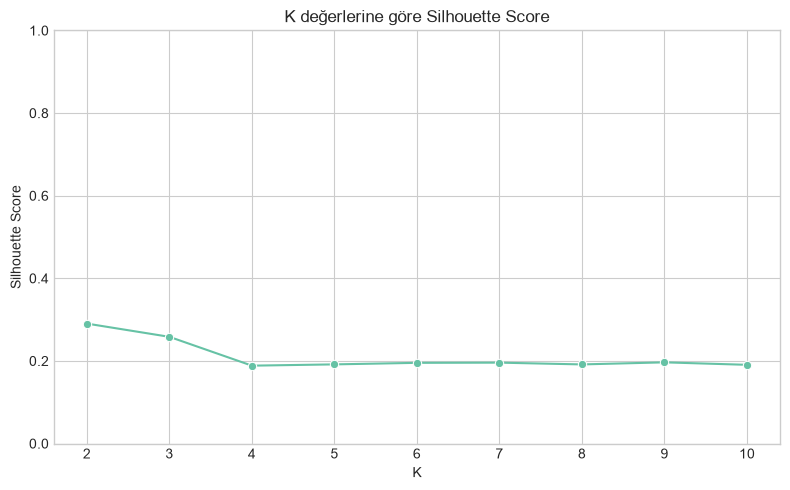

In [20]:
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
)

metric_records = []
for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = model.fit_predict(X_scaled)
    metric_records.append({
        "K": k,
        "Inertia (Elbow)": model.inertia_,
        "Silhouette Score": silhouette_score(X_scaled, labels),
        "Davies-Bouldin (DB)": davies_bouldin_score(X_scaled, labels),
        "Calinski-Harabasz (CH)": calinski_harabasz_score(X_scaled, labels),
    })

selection_results = pd.DataFrame(metric_records)
display(selection_results.round(3))

best_silhouette = selection_results.loc[selection_results["Silhouette Score"].idxmax(), "K"]
best_db = selection_results.loc[selection_results["Davies-Bouldin (DB)"].idxmin(), "K"]
best_ch = selection_results.loc[selection_results["Calinski-Harabasz (CH)"].idxmax(), "K"]
print(f"En yüksek Silhouette Score: K={best_silhouette}")
print(f"En düşük Davies-Bouldin (DB): K={best_db}")
print(f"En yüksek Calinski-Harabasz (CH): K={best_ch}")

plt.figure(figsize=(8, 5))
sns.lineplot(data=selection_results, x="K", y="Silhouette Score", marker="o")
plt.title("K değerlerine göre Silhouette Score")
plt.xticks(list(k_values))
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

Elbow grafiği K arttıkça doğal olarak azalır; ancak en güçlü sayısal ayrım Silhouette Score ile **K=2** değerinde görülür. Bu nedenle yorumlanabilir ve daha iyi ayrışan iki müşteri segmentiyle devam ediyoruz.

## 15. Final K-Means modeli

Seçilen K=2 ile final modeli kuruyor ve her müşteriye bir küme etiketi ekliyoruz. Etiketler sıralı bir önem anlamı taşımaz; yalnızca küme kimliğidir.

In [21]:
best_k = 2
final_kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=20)
labels = final_kmeans.fit_predict(X_scaled)
df["Cluster"] = labels

cluster_counts = df["Cluster"].value_counts().sort_index()
display(cluster_counts.rename("Müşteri Sayısı").to_frame())

,Müşteri Sayısı
Cluster,
0,252
1,188


## 16. PCA ile görselleştirme

PCA, çok boyutlu veriyi bilgiyi mümkün olduğunca koruyarak daha az boyutta temsil etmeye yarar. Burada altı harcama özelliğini iki bileşene indirerek K-Means kümelerini düzlemde inceliyoruz.

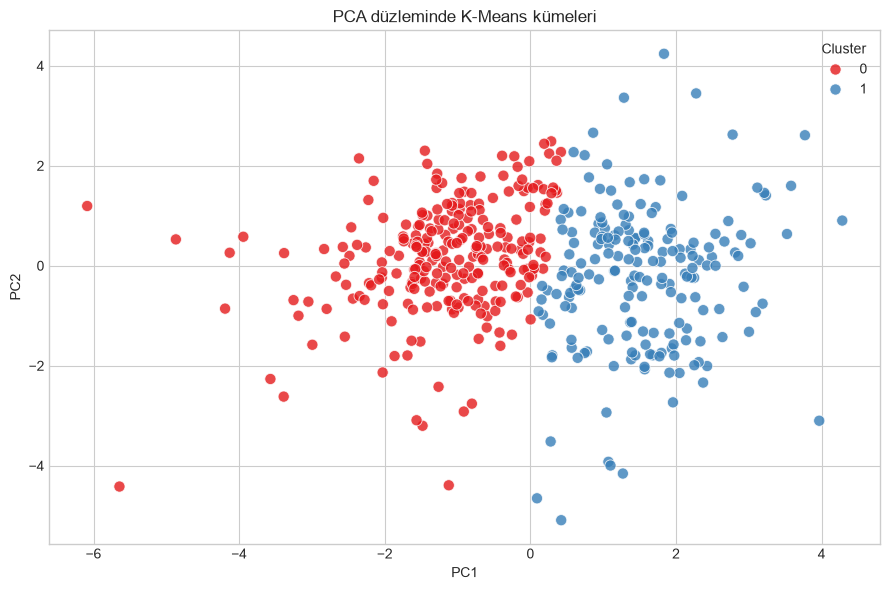

İlk iki bileşenin açıkladığı toplam varyans: 71.3%


In [22]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"], index=df.index)
pca_df["Cluster"] = df["Cluster"]

plt.figure(figsize=(9, 6))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="Cluster", palette="Set1", s=65, alpha=0.8)
plt.title("PCA düzleminde K-Means kümeleri")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

print(f"İlk iki bileşenin açıkladığı toplam varyans: {pca.explained_variance_ratio_.sum():.1%}")

PCA grafiği iki kümenin genel yerleşimini görmeyi sağlar. İki boyut tüm bilgiyi taşımaz; bu yüzden grafiği, küme profilleriyle birlikte yorumlamak daha güvenlidir.

## 17. Cluster analizi

Kümeleri anlamlandırmak için her harcama kategorisindeki ortalamaları karşılaştırıyoruz. Verilecek isimler kesin sınıflar değil, bu ortalama profillere dayalı yorumlardır.

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster,,,,,,
0,"13,973.13","2,401.75","2,918.71","3,705.67",491.94,"1,038.04"
1,"9,355.87","10,346.36","14,697.06","2,222.45","6,084.51","2,177.43"


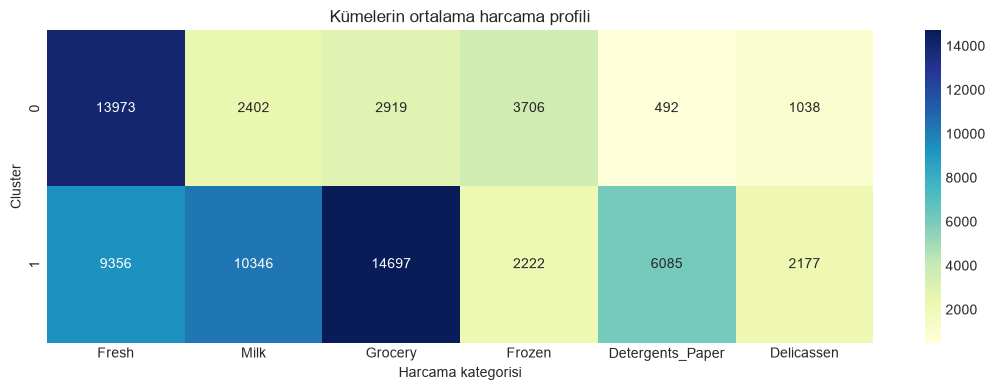

In [23]:
cluster_profile = df.groupby("Cluster")[spending_cols].mean()
display(cluster_profile.round(2))

plt.figure(figsize=(11, 4))
sns.heatmap(cluster_profile, annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("Kümelerin ortalama harcama profili")
plt.xlabel("Harcama kategorisi")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()

In [24]:
overall_mean = df[spending_cols].mean()
relative_profile = cluster_profile.div(overall_mean, axis=1)
display(relative_profile.round(2))

for cluster_id, row in relative_profile.iterrows():
    strongest = row.idxmax()
    weakest = row.idxmin()
    total_level = cluster_profile.loc[cluster_id].mean() / overall_mean.mean()
    print(
        f"Cluster {cluster_id}: en belirgin göreli harcama '{strongest}', "
        f"en düşük göreli harcama '{weakest}'. Genel harcama düzeyi: {total_level:.0%}."
    )

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster,,,,,,
0,1.16,0.41,0.37,1.21,0.17,0.68
1,0.78,1.79,1.85,0.72,2.11,1.43


Cluster 0: en belirgin göreli harcama 'Frozen', en düşük göreli harcama 'Detergents_Paper'. Genel harcama düzeyi: 74%.
Cluster 1: en belirgin göreli harcama 'Detergents_Paper', en düşük göreli harcama 'Frozen'. Genel harcama düzeyi: 135%.


Isı haritası, kümelerin yalnızca büyüklük değil harcama bileşimi bakımından da ayrıldığını gösterir. Örneğin bir kümeye **market/süt ürünleri ağırlıklı**, diğerine **taze ürün ağırlıklı** gibi yorumlayıcı adlar verilebilir; bu adlar iş bağlamıyla doğrulanmalıdır.

## 18. Segmentlerin Channel ve Region dağılımı

Kümelerin harcama profilleri kadar satış kanalı ve bölge dağılımları da iş açısından önemlidir. Aşağıdaki tablolar, her küme içindeki müşterilerin yüzde olarak hangi `Channel` ve `Region` kodunda yer aldığını gösterir; böylece küme büyüklükleri karşılaştırmayı yanıltmaz.

In [25]:
# Küme içindeki Channel ve Region yüzdelerini hesaplıyoruz.
channel_counts = pd.crosstab(df["Cluster"], df["Channel"])
channel_pct = pd.crosstab(df["Cluster"], df["Channel"], normalize="index").mul(100)
region_counts = pd.crosstab(df["Cluster"], df["Region"])
region_pct = pd.crosstab(df["Cluster"], df["Region"], normalize="index").mul(100)

print("Cluster × Channel — müşteri adetleri")
display(channel_counts)
print("Cluster × Channel — küme içi yüzde")
display(channel_pct.round(1))

print("Cluster × Region — müşteri adetleri")
display(region_counts)
print("Cluster × Region — küme içi yüzde")
display(region_pct.round(1))


Cluster × Channel — müşteri adetleri


Channel,1,2
Cluster,,
0,244,8
1,54,134


Cluster × Channel — küme içi yüzde


Channel,1,2
Cluster,,
0,96.80,3.20
1,28.70,71.30


Cluster × Region — müşteri adetleri


Region,1,2,3
Cluster,,,
0,48,28,176
1,29,19,140


Cluster × Region — küme içi yüzde


Region,1,2,3
Cluster,,,
0,19.00,11.10,69.80
1,15.40,10.10,74.50


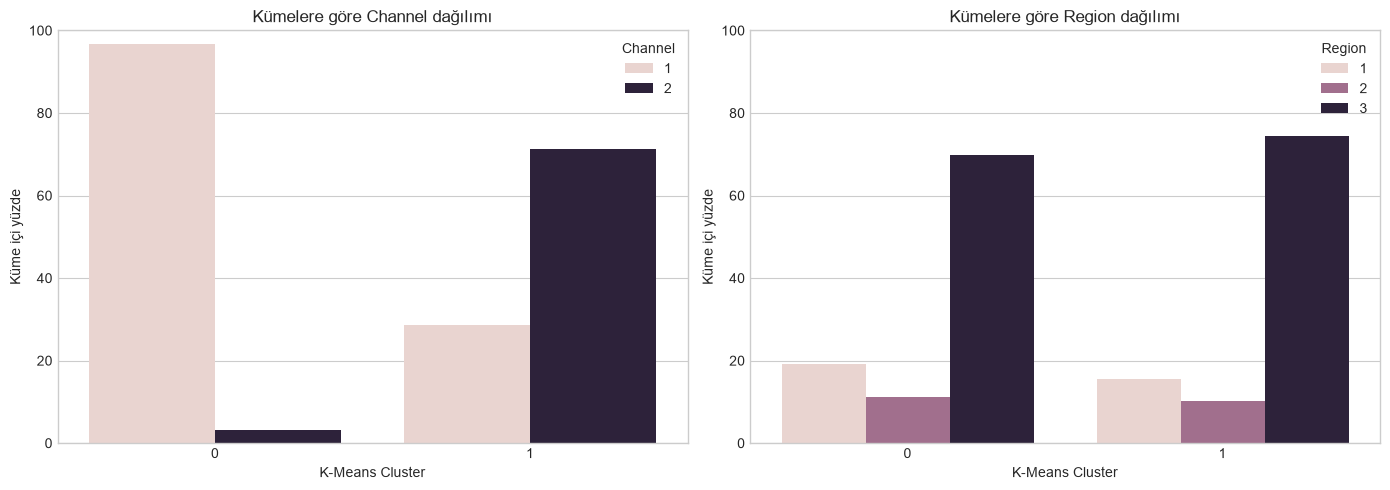

In [26]:
# Yüzde grafikleri, her segmentin kategori içindeki bileşimini karşılaştırır.
channel_plot = channel_pct.rename_axis("Cluster").reset_index().melt(
    id_vars="Cluster", var_name="Channel", value_name="Yüzde"
)
region_plot = region_pct.rename_axis("Cluster").reset_index().melt(
    id_vars="Cluster", var_name="Region", value_name="Yüzde"
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=channel_plot, x="Cluster", y="Yüzde", hue="Channel", ax=axes[0])
axes[0].set_title("Kümelere göre Channel dağılımı")
axes[0].set_xlabel("K-Means Cluster")
axes[0].set_ylabel("Küme içi yüzde")
axes[0].set_ylim(0, 100)
axes[0].legend(title="Channel")

sns.barplot(data=region_plot, x="Cluster", y="Yüzde", hue="Region", ax=axes[1])
axes[1].set_title("Kümelere göre Region dağılımı")
axes[1].set_xlabel("K-Means Cluster")
axes[1].set_ylabel("Küme içi yüzde")
axes[1].set_ylim(0, 100)
axes[1].legend(title="Region")

plt.tight_layout()
plt.show()


### Segment isimleri ve iş önerileri

Küme etiketleri algoritmanın verdiği numaralardır; aşağıdaki isimler ortalama harcama profilinden türetilen iş yorumlarıdır. Bunlar kesin müşteri türleri değildir; satış ekibinin saha bilgisiyle doğrulanmalıdır.

In [27]:
segment_names = {
    0: "Taze ve dondurulmuş ürün odaklı müşteriler",
    1: "Market, süt ve deterjan-kâğıt ağırlıklı müşteriler",
}

business_actions = {
    0: "Taze ürün sepetine dondurulmuş ürün çapraz satışı, küçük paket kampanyaları ve mevsimsel tekliflere odaklanılabilir.",
    1: "Yüksek hacimli market/süt/deterjan-kâğıt alımlarına toplu alım indirimi, sadakat avantajı ve kategori bazlı paket teklifleri uygulanabilir.",
}

for cluster_id in sorted(df["Cluster"].unique()):
    dominant_channel = channel_pct.loc[cluster_id].idxmax()
    dominant_region = region_pct.loc[cluster_id].idxmax()
    print(f"Cluster {cluster_id} — {segment_names[cluster_id]}")
    print(
        f"  En yoğun Channel: {dominant_channel} "
        f"(%{channel_pct.loc[cluster_id, dominant_channel]:.1f}) | "
        f"En yoğun Region: {dominant_region} "
        f"(%{region_pct.loc[cluster_id, dominant_region]:.1f})"
    )
    print(f"  İş önerisi: {business_actions[cluster_id]}\n")


Cluster 0 — Taze ve dondurulmuş ürün odaklı müşteriler
  En yoğun Channel: 1 (%96.8) | En yoğun Region: 3 (%69.8)
  İş önerisi: Taze ürün sepetine dondurulmuş ürün çapraz satışı, küçük paket kampanyaları ve mevsimsel tekliflere odaklanılabilir.

Cluster 1 — Market, süt ve deterjan-kâğıt ağırlıklı müşteriler
  En yoğun Channel: 2 (%71.3) | En yoğun Region: 3 (%74.5)
  İş önerisi: Yüksek hacimli market/süt/deterjan-kâğıt alımlarına toplu alım indirimi, sadakat avantajı ve kategori bazlı paket teklifleri uygulanabilir.



Bu bölüm, K-Means kümelerini yalnızca teknik gruplar olmaktan çıkarıp hedeflenebilir müşteri segmentlerine dönüştürür. Özellikle yüzde dağılımları, belirli bir kanal veya bölgedeki segment yoğunluğunu müşteri sayısından bağımsız biçimde karşılaştırmayı sağlar.

## 18. Hiyerarşik kümeleme

Hiyerarşik kümeleme, gözlemleri veya küçük kümeleri adım adım birleştirerek bir küme ağacı oluşturur. Burada `AgglomerativeClustering` ve Ward bağlantı yöntemini kullanıyoruz; Ward, küme içi varyansı mümkün olduğunca düşük tutacak birleşmeleri seçer. K-Means'ten farklı olarak birleşme sürecini dendrogram üzerinde inceleyebiliriz.

### Dendrogram

Dendrogram, kümelerin hangi uzaklıklarda birleştiğini gösteren ağaç grafiğidir. 440 gözlemin tamamını tek tek göstermek okunabilir olmayacağı için son birleşmeleri özetleyen kısaltılmış bir dendrogram kullanıyoruz. Daha büyük dikey sıçramalar, farklı kümeler arasındaki belirgin ayrımlara işaret edebilir.

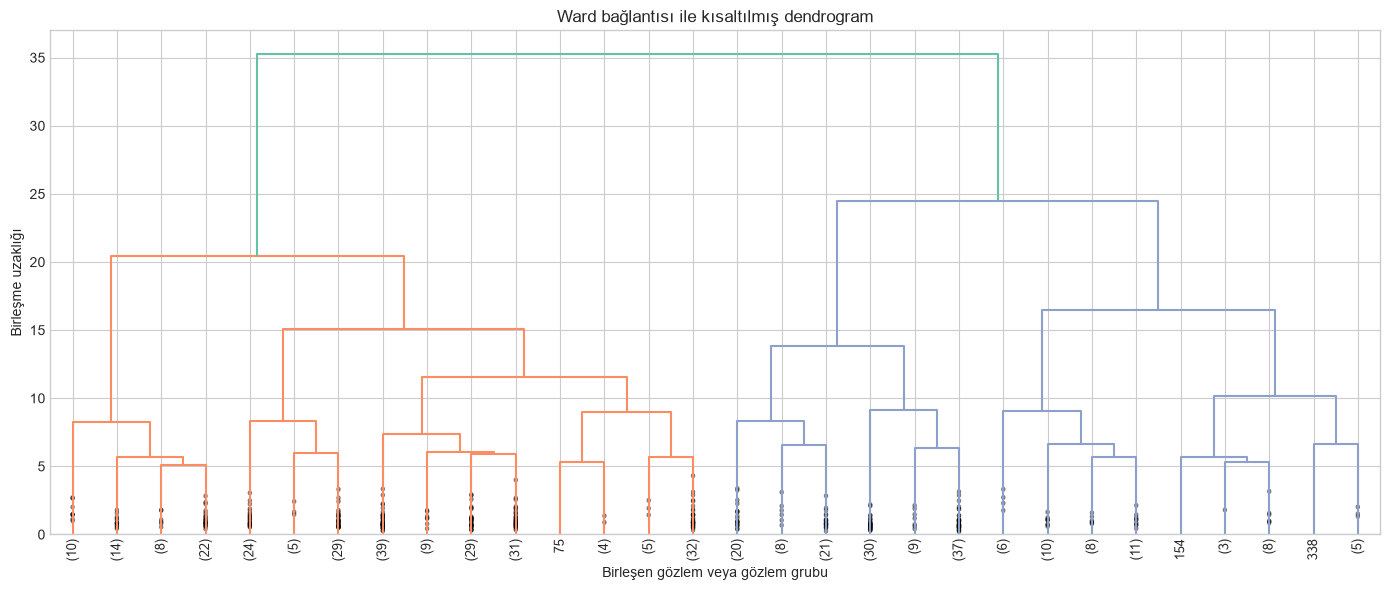

In [28]:
from scipy.cluster.hierarchy import dendrogram, linkage

ward_linkage = linkage(X_scaled, method="ward")

plt.figure(figsize=(14, 6))
dendrogram(
    ward_linkage,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=90,
    leaf_font_size=9,
    show_contracted=True,
)
plt.title("Ward bağlantısı ile kısaltılmış dendrogram")
plt.xlabel("Birleşen gözlem veya gözlem grubu")
plt.ylabel("Birleşme uzaklığı")
plt.tight_layout()
plt.show()


### K sayısının metriklerle değerlendirilmesi

K-Means ile adil bir karşılaştırma yapmak için hiyerarşik modelde de K=2–10 aralığını deniyoruz. Silhouette ve Calinski-Harabasz değerlerinde yüksek, Davies-Bouldin değerinde düşük sonuç daha iyi ayrışmaya işaret eder.

,K,Silhouette Score,Davies-Bouldin (DB),Calinski-Harabasz (CH)
0,2,0.26,1.60,134.62
1,3,0.26,1.54,116.80
2,4,0.20,1.52,108.61
3,5,0.20,1.39,100.02
4,6,0.17,1.49,94.86
5,7,0.16,1.50,91.30
6,8,0.15,1.59,86.61
7,9,0.15,1.55,82.01
8,10,0.12,1.50,77.72


En yüksek Silhouette Score: K=2
En düşük Davies-Bouldin (DB): K=5
En yüksek Calinski-Harabasz (CH): K=2


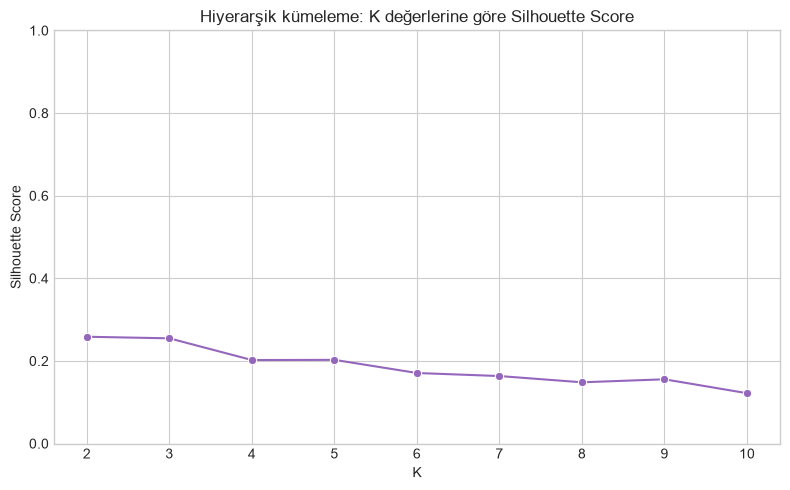

In [29]:
from sklearn.cluster import AgglomerativeClustering

hierarchical_records = []
for k in k_values:
    hierarchical_model = AgglomerativeClustering(n_clusters=k, linkage="ward")
    hierarchical_labels = hierarchical_model.fit_predict(X_scaled)
    hierarchical_records.append({
        "K": k,
        "Silhouette Score": silhouette_score(X_scaled, hierarchical_labels),
        "Davies-Bouldin (DB)": davies_bouldin_score(X_scaled, hierarchical_labels),
        "Calinski-Harabasz (CH)": calinski_harabasz_score(X_scaled, hierarchical_labels),
    })

hierarchical_results = pd.DataFrame(hierarchical_records)
display(hierarchical_results.round(3))

best_hierarchical_k = int(
    hierarchical_results.loc[hierarchical_results["Silhouette Score"].idxmax(), "K"]
)
best_hierarchical_db = int(
    hierarchical_results.loc[hierarchical_results["Davies-Bouldin (DB)"].idxmin(), "K"]
)
best_hierarchical_ch = int(
    hierarchical_results.loc[hierarchical_results["Calinski-Harabasz (CH)"].idxmax(), "K"]
)
print(f"En yüksek Silhouette Score: K={best_hierarchical_k}")
print(f"En düşük Davies-Bouldin (DB): K={best_hierarchical_db}")
print(f"En yüksek Calinski-Harabasz (CH): K={best_hierarchical_ch}")

plt.figure(figsize=(8, 5))
sns.lineplot(data=hierarchical_results, x="K", y="Silhouette Score", marker="o", color="tab:purple")
plt.title("Hiyerarşik kümeleme: K değerlerine göre Silhouette Score")
plt.xticks(list(k_values))
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


### Seçilen hiyerarşik model ve K-Means karşılaştırması

Silhouette sonucuna göre seçilen K ile modeli tekrar kuruyoruz. Aynı müşteri için K-Means ve hiyerarşik küme etiketleri farklı numaralar kullanabilir; bu nedenle etiketlerin sayısından çok müşteri gruplarının örtüşmesine bakılır.

In [30]:
final_hierarchical = AgglomerativeClustering(
    n_clusters=best_hierarchical_k,
    linkage="ward",
)
df["Hierarchical_Cluster"] = final_hierarchical.fit_predict(X_scaled)

display(
    df["Hierarchical_Cluster"]
    .value_counts()
    .sort_index()
    .rename("Müşteri Sayısı")
    .to_frame()
)

comparison_table = pd.crosstab(
    df["Cluster"],
    df["Hierarchical_Cluster"],
    rownames=["K-Means Cluster"],
    colnames=["Hiyerarşik Cluster"],
)
display(comparison_table)


,Müşteri Sayısı
Hierarchical_Cluster,
0,178
1,262


Hiyerarşik Cluster,0,1
K-Means Cluster,,
0,17,235
1,161,27


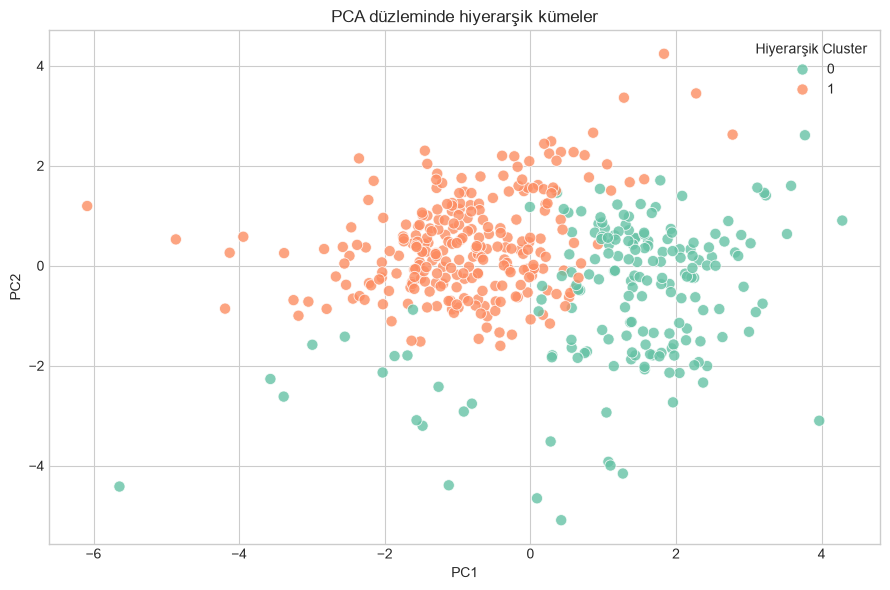

In [31]:
hierarchical_pca_df = pca_df.copy()
hierarchical_pca_df["Hierarchical_Cluster"] = df["Hierarchical_Cluster"]

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=hierarchical_pca_df,
    x="PC1",
    y="PC2",
    hue="Hierarchical_Cluster",
    palette="Set2",
    s=65,
    alpha=0.8,
)
plt.title("PCA düzleminde hiyerarşik kümeler")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Hiyerarşik Cluster")
plt.tight_layout()
plt.show()


### PCA ile 2 boyutlu karşılaştırma

PCA, altı harcama özelliğini iki görsel bileşene indirger. Aynı PCA koordinatlarını kullanarak K-Means ve hiyerarşik kümeleme sonuçlarını yan yana görmek, yöntemlerin müşterileri nasıl ayırdığını daha kolay karşılaştırmamızı sağlar.

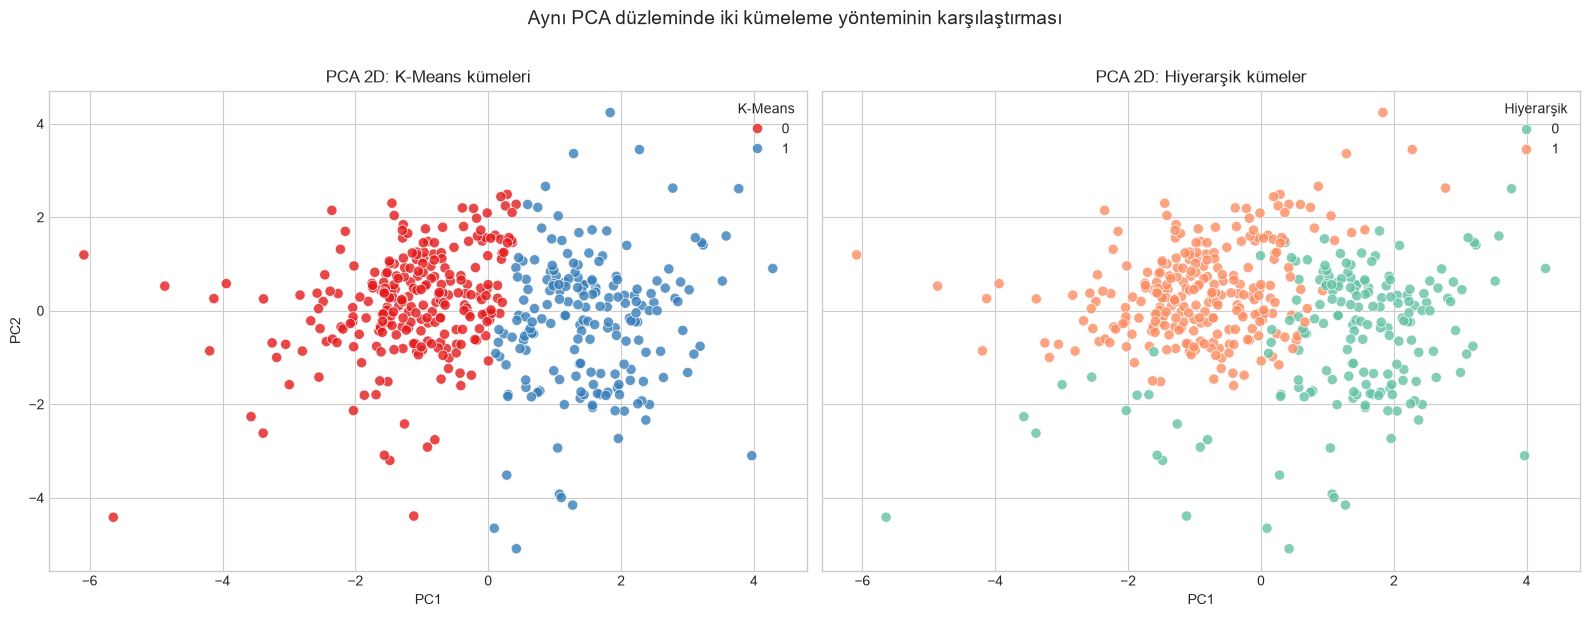

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True, sharey=True)

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set1",
    s=55,
    alpha=0.8,
    ax=axes[0],
)
axes[0].set_title("PCA 2D: K-Means kümeleri")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[0].legend(title="K-Means")

sns.scatterplot(
    data=hierarchical_pca_df,
    x="PC1",
    y="PC2",
    hue="Hierarchical_Cluster",
    palette="Set2",
    s=55,
    alpha=0.8,
    ax=axes[1],
)
axes[1].set_title("PCA 2D: Hiyerarşik kümeler")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
axes[1].legend(title="Hiyerarşik")

fig.suptitle("Aynı PCA düzleminde iki kümeleme yönteminin karşılaştırması", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()


### Hiyerarşik cluster profiling

Kümeleri iş açısından anlamlandırmak için her kümenin ortalama harcama profilini hesaplıyoruz. Isı haritasındaki değerler gerçek yıllık harcama ortalamalarıdır; bu nedenle hangi kümenin hangi ürün kategorisine daha çok yöneldiği görülebilir.

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Hierarchical_Cluster,,,,,,
0,"7,561.31","9,338.17","14,247.11","1,429.40","6,214.91","1,483.83"
1,"15,016.10","3,389.94","3,673.95","4,187.85",616.81,"1,552.75"


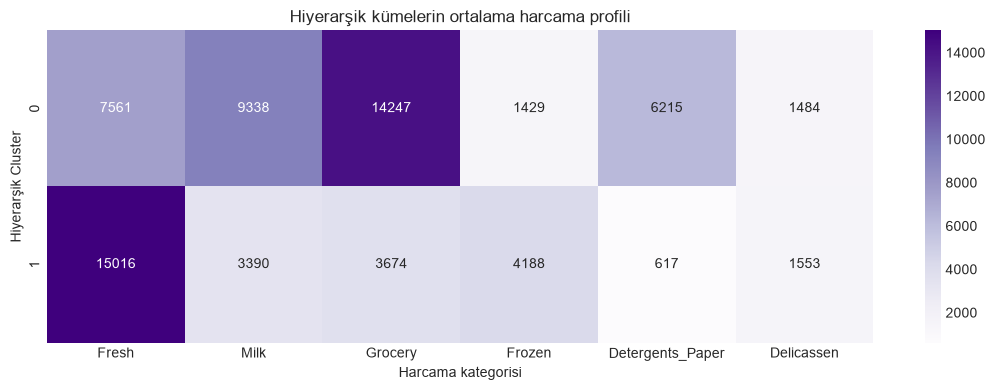

In [33]:
hierarchical_profile = df.groupby("Hierarchical_Cluster")[spending_cols].mean()
display(hierarchical_profile.round(2))

plt.figure(figsize=(11, 4))
sns.heatmap(hierarchical_profile, annot=True, fmt=".0f", cmap="Purples")
plt.title("Hiyerarşik kümelerin ortalama harcama profili")
plt.xlabel("Harcama kategorisi")
plt.ylabel("Hiyerarşik Cluster")
plt.tight_layout()
plt.show()


In [34]:
# Genel ortalamaya göre oranlar, kümelerin göreli güçlü yönlerini daha net gösterir.
hierarchical_relative_profile = hierarchical_profile.div(df[spending_cols].mean(), axis=1)
display(hierarchical_relative_profile.round(2))

for cluster_id, row in hierarchical_relative_profile.iterrows():
    strongest = row.idxmax()
    weakest = row.idxmin()
    overall_level = hierarchical_profile.loc[cluster_id].mean() / df[spending_cols].mean().mean()
    print(
        f"Hiyerarşik Cluster {cluster_id}: en belirgin göreli kategori '{strongest}', "
        f"en düşük göreli kategori '{weakest}', genel harcama düzeyi {overall_level:.0%}."
    )


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Hierarchical_Cluster,,,,,,
0,0.63,1.61,1.79,0.47,2.16,0.97
1,1.25,0.58,0.46,1.36,0.21,1.02


Hiyerarşik Cluster 0: en belirgin göreli kategori 'Detergents_Paper', en düşük göreli kategori 'Frozen', genel harcama düzeyi 121%.
Hiyerarşik Cluster 1: en belirgin göreli kategori 'Frozen', en düşük göreli kategori 'Detergents_Paper', genel harcama düzeyi 86%.


PCA grafiği kümelerin iki boyutlu görünümünü verir; profil tablosu ise bu ayrımın hangi harcama davranışlarından kaynaklandığını açıklar. Bu iki görünüm birlikte kullanıldığında hem görsel hem de iş odaklı bir cluster değerlendirmesi yapılabilir.

Hiyerarşik kümeleme, aynı ön işlenmiş veri üzerinde K-Means'e alternatif bir bakış sunar. Metrik tablosu ve çapraz tablo, iki yöntemin benzer müşteri gruplarına ulaşıp ulaşmadığını değerlendirirken kullanılmalıdır.

## 18. DBSCAN ile kısa karşılaştırma

DBSCAN yoğunluk bazlı çalışır; küme sayısını önceden vermek gerekmez. Seyrek bölgelerde kalan gürültü veya aykırı noktaları `-1` etiketiyle işaretleyebilir. Aşağıdaki küçük denemeler parametre duyarlılığını gösterir.

In [35]:
from sklearn.cluster import DBSCAN

dbscan_trials = []
for eps in [0.5, 0.7, 0.9, 1.1]:
    for min_samples in [5, 10]:
        db_labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)
        unique_labels = set(db_labels)
        n_clusters = len(unique_labels) - (1 if -1 in unique_labels else 0)
        n_noise = int((db_labels == -1).sum())
        dbscan_trials.append({
            "eps": eps,
            "min_samples": min_samples,
            "Küme sayısı": n_clusters,
            "Gürültü noktası (-1)": n_noise,
        })

dbscan_results = pd.DataFrame(dbscan_trials)
display(dbscan_results)

,eps,min_samples,Küme sayısı,Gürültü noktası (-1)
0,0.50,5,1,435
1,0.50,10,0,440
2,0.70,5,4,343
3,0.70,10,1,422
4,0.90,5,3,160
5,0.90,10,2,248
6,1.10,5,1,96
7,1.10,10,2,122


DBSCAN sonuçları parametreye oldukça duyarlıdır ve birçok gözlemi gürültü olarak işaretleyebilir. Bu nedenle bu veri ve başlangıç seviyesi amaç için K-Means ana yöntem olarak daha kolay yorumlanabilir bir seçimdir.

## 19. Proje sonucu

- Veri setinde 440 toptancı müşterisinin altı harcama kategorisindeki davranışı incelendi.
- Eksik değer ve tekrar eden kayıt bulunmadı; veri temizliğinde ek düzeltme gerekmedi.
- Harcama dağılımları sağa çarpıktı ve yüksek harcama yapan müşteriler vardı.
- Log dönüşümü çarpıklığın, scaling ise büyük ölçekli sütunların uzaklık üzerindeki baskınlığının azaltılması için uygulandı.
- Elbow ve özellikle Silhouette Score değerlendirmesi sonucunda K-Means ile **2 müşteri segmenti** seçildi.
- PCA, kümelerin iki boyutlu görünümünü sundu; ayrıntılı yorum için profil tablosu ile birlikte kullanıldı.
- Küme profilleri taze ürün ile market/süt/deterjan-kâğıt harcaması ekseninde farklılaşan müşteri davranışlarını gösterdi.
- K-Means küme sayısını baştan ister ve merkez tabanlıdır; DBSCAN ise yoğunluk tabanlıdır, küme sayısını önceden istemez ve gürültü noktalarını ayırabilir.

### Bu projede öğrenilen kavramlar

- Exploratory Data Analysis
- Missing Value Analysis
- Duplicate Analysis
- Distribution Analysis
- Outlier Analysis
- Correlation
- Feature Scaling
- Log Transformation
- K-Means
- Elbow Method
- Silhouette Score
- PCA
- Cluster Profiling
- DBSCAN

## 20. Nihai Model Kararı ve Yönetici Özeti

Bu projede nihai segmentasyon modeli olarak **K-Means (K=2)** seçilmiştir. Aynı ön işlenmiş veri üzerinde Ward bağlantılı hiyerarşik kümeleme de denendi; ancak K-Means hem daha güçlü küme ayrımı hem de daha kolay uygulanabilir ve yorumlanabilir bir sonuç sundu. Hiyerarşik yöntem, dendrogram ile keşifsel doğrulama amacıyla korunmuştur.

### Model karşılaştırması ve karar

| Ölçüt (K=2) | K-Means | Hiyerarşik / Ward | Tercih |
|---|---:|---:|---|
| Silhouette Score — yüksek iyi | **0.290** | 0.258 | K-Means |
| Davies-Bouldin — düşük iyi | **1.352** | 1.600 | K-Means |
| Calinski-Harabasz — yüksek iyi | **189.050** | 134.624 | K-Means |

K-Means, üç kalite metriğinde de daha güçlü sonuç verdiği için nihai modeldir. K=2 seçimi iki ayrı, yorumlanabilir müşteri davranışını ortaya çıkarmaktadır.

### Segment özeti ve önerilen aksiyonlar

| Segment | Temel profil | Kanal / Bölge yoğunluğu | Önerilen aksiyon |
|---|---|---|---|
| Cluster 0 | Taze ve dondurulmuş ürün odaklı; görece daha düşük toplam harcama | Channel 1: %96.8; Region 3: %69.8 | Taze ve dondurulmuş ürün çapraz satışı, küçük paketler ve mevsimsel kampanyalar |
| Cluster 1 | Market, süt ve deterjan-kâğıt ürünlerinde yüksek harcama; daha yüksek hacim | Channel 2: %71.3; Region 3: %74.5 | Toplu alım indirimi, sadakat avantajı ve kategori bazlı paketler |

Bu öneriler harcama verisine dayanır. Kampanya uygulamasından önce ürün kârlılığı, stok durumu ve satış ekibinin müşteri bilgisiyle doğrulanmalıdır.

### Kısa sonuç

Veri setinde eksik veya tekrar eden kayıt bulunmadı; harcama değişkenleri sağa çarpık olduğu için `log1p` dönüşümü ve ölçeklendirme uygulandı. PCA, iki segmentin görsel olarak incelenmesini sağladı; cluster profiling ise bu ayrımın taze/dondurulmuş ürünler ile market-süt-deterjan/kâğıt harcamalarından kaynaklandığını gösterdi. Bu çalışma, müşteri segmentasyonu için veriye dayalı kampanya ve satış stratejisi geliştirmede başlangıç noktası olarak kullanılabilir.